<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week06/%EC%86%90%EA%B8%80%EC%94%A8_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 손글씨 숫자 분류 — 딥러닝

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. 라이브러리 및 데이터 불러오기

이미지 shape: (1797, 8, 8)
레이블: [0 1 2 3 4 5 6 7 8 9]


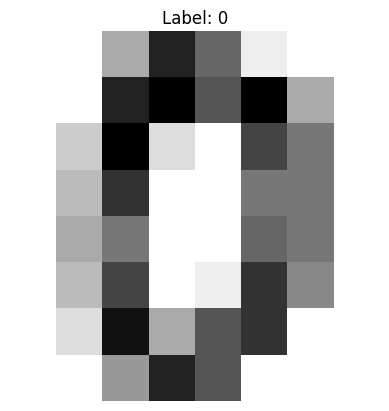

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(42)
digits = datasets.load_digits()
print("이미지 shape:", digits.images.shape)
print("레이블:", np.unique(digits.target))
plt.imshow(digits.images[0], cmap=plt.cm.gray_r, interpolation="nearest")
plt.title(f"Label: {digits.target[0]}")
plt.axis("off")
plt.show()

## 2. 이미지 펼치기 및 데이터 분리
8×8 이미지를 64개 입력 특성으로 변환한다.

In [5]:
n_samples = len(digits.images)
X = digits.images.reshape((n_samples, -1))
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (1437, 64) X_test: (360, 64)


## 3. 입력 정규화 및 정답 원-핫 인코딩
`categorical_crossentropy`를 사용하므로 정답을 10개 열로 원-핫 인코딩한다.

In [6]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Y_train = pd.get_dummies(y_train).reindex(columns=range(10), fill_value=0).values.astype("float32")
Y_test = pd.get_dummies(y_test).reindex(columns=range(10), fill_value=0).values.astype("float32")
print("원-핫 인코딩 전:", y_train[:5])
print("원-핫 인코딩 후:\n", Y_train[:5])

원-핫 인코딩 전: [5 0 5 7 1]
원-핫 인코딩 후:
 [[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]]


## 4. 딥러닝 모델 생성


In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,778 (10.85 KB)

 Trainable params: 2,778 (10.85 KB)

 Non-trainable params: 0 (0.00 B)

## 5. 컴파일 및 학습

In [8]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history = model.fit(
    X_train, Y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.1967 - loss: 2.1809 - val_accuracy: 0.2465 - val_loss: 2.0477
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4230 - loss: 1.7809 - val_accuracy: 0.4236 - val_loss: 1.7450
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6110 - loss: 1.4106 - val_accuracy: 0.6042 - val_loss: 1.4077
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7267 - loss: 1.0484 - val_accuracy: 0.6875 - val_loss: 1.0723
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8016 - loss: 0.7557 - val_accuracy: 0.8056 - val_loss: 0.8176
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8982 - loss: 0.5449 - val_accuracy: 0.8611 - val_loss: 0.6439
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9321 - loss: 0.3986 - val_accuracy: 0.8889 - val_loss: 0.5280
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9434 - loss: 0.3009 - val_accuracy: 0.8993 - v

## 6. 테스트 데이터 평가

In [9]:
test_loss, test_accuracy = model.evaluate(X_test, Y_test, verbose=0)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
print("\nClassification Report:\n", metrics.classification_report(y_test, y_pred, zero_division=0))
print("Confusion Matrix:\n", metrics.confusion_matrix(y_test, y_pred))

Test Loss: 0.15858718752861023
Test Accuracy: 0.9666666388511658
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.90      0.97      0.93        36
           2       0.97      1.00      0.99        35
           3       0.97      1.00      0.99        37
           4       1.00      0.97      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       0.86      1.00      0.92        36
           8       1.00      0.80      0.89        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360

Confusion Matrix:
 [[35  0  1  0  0  0  0  0  0  0]
 [ 0 35  0  0  0  0  0  1  0  0]
 [ 0  0 35  0  0  0  0  0 

## 7. 학습 정확도 시각화

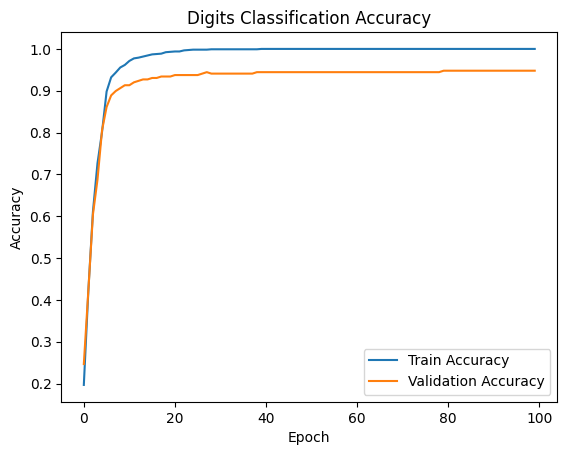

In [10]:
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Digits Classification Accuracy")
plt.legend()
plt.show()

## 8. 테스트 이미지 하나 예측
표준화된 `X_test`는 이미지 표시용으로 적합하지 않으므로 원래 픽셀 값으로 되돌려 시각화한다.

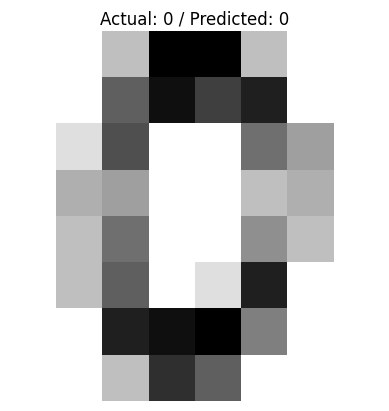

실제 정답: 0
딥러닝 예측: 0


In [11]:
idx = 10
original_image = scaler.inverse_transform(X_test[idx:idx+1])[0].reshape(8, 8)
plt.imshow(original_image, cmap=plt.cm.gray_r, interpolation="nearest")
plt.title(f"Actual: {y_test[idx]} / Predicted: {y_pred[idx]}")
plt.axis("off")
plt.show()
print("실제 정답:", y_test[idx])
print("딥러닝 예측:", y_pred[idx])